# Chart encoding checks for the hotel bookings dashboard

**Data sources:** `data/processed/hotel_bookings_clean.csv` (Part 1) and `data/processed/country_names.csv` (Part 3), from Antonio, de Almeida and Nunes (2019).
**Date:** 2026-11-05, updated 2026-11-09 for the refined dashboard
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** Evidence for Part 4 (tasks 4.1 and 4.2): the cardinality of every field we encode, the DRACO hard-rule check of every chart, and the contrast and colour-blindness checks of the colours in the light and the night theme. The charts are those of the refined dashboard (students' decisions of 9 November: Okabe–Ito colours, night mode, calendar heatmap, dumbbell, animated bubbles and box plots). No dashboard chart is built here; that is Part 6.

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration: cardinalities](#2.-Initial-exploration:-cardinalities)
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: DRACO hard rules and colour checks](#4.-Analysis:-DRACO-hard-rules-and-colour-checks)
5. [Accessible visualisation: the palette](#5.-Accessible-visualisation:-the-palette)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

CLEAN_FILE   = Path('../../data/processed/hotel_bookings_clean.csv')
NAMES_FILE   = Path('../../data/processed/country_names.csv')
OUTPUT_DIR   = Path('encoding_checks_output')
IMAGES_DIR   = Path('../images')
OUTPUT_DIR.mkdir(exist_ok=True)
IMAGES_DIR.mkdir(exist_ok=True)

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8})
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__,
      '| matplotlib', matplotlib.__version__)

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | matplotlib 3.11.2


## 1. Data loading

In [2]:
# ── Load the cleaned bookings and the country names ──────────────────────────
bookings = pd.read_csv(CLEAN_FILE, keep_default_na=False)
names = pd.read_csv(NAMES_FILE, keep_default_na=False)
bookings = bookings.merge(names[['country', 'country_name']], on='country', how='left')
bookings['arrival_date'] = pd.to_datetime(bookings['arrival_date'])
print(f'Rows: {len(bookings):,} | bookings without a country name: {bookings["country_name"].isna().sum()}')

Rows: 119,201 | bookings without a country name: 0


## 2. Initial exploration: cardinalities

DRACO limits the number of categories per channel (for example at most 20 colours, at most 8 shapes, and at most 50 values on an axis), and the skills limit categorical colours to 7. These are the values each encoding shows. The top 10 countries are ranked by guests of stays (bookings not cancelled), as in the dashboard; a country outside the top 10 can be chosen from a list if it has at least 20 stays.

In [3]:
# ── Number of distinct values per encoding ────────────────────────────────────
stays = bookings[bookings['is_canceled'] == 0]
guests_by_country = stays.groupby('country_name')['total_guests'].sum().sort_values(ascending=False)
top_10_countries = guests_by_country.drop('Unknown', errors='ignore').head(10).index.tolist()
stays_per_country = stays[~stays['country_name'].isin(top_10_countries + ['Unknown'])].groupby('country_name').size()
list_countries = sorted(stays_per_country[stays_per_country >= 20].index)

cardinality = pd.Series({
    'hotel (colour + line style + point shape)': bookings['hotel'].nunique(),
    'arrival month, timeline (x axis of C1 and C3)': bookings['arrival_date'].dt.to_period('M').nunique(),
    'calendar month (columns of C2, frames of C9)': bookings['arrival_date'].dt.month.nunique(),
    'hotel and year (rows of C2)': bookings.groupby(['hotel', bookings['arrival_date'].dt.year]).ngroups,
    'classes of % cancelled (colour of C2)': 7,
    'countries on the axis: top 10 + Other (C4, C7, C8)': len(top_10_countries) + 1,
    'countries on the axis with one chosen from the list': len(top_10_countries) + 2,
    'bubbles: top 10, plus one chosen from the list (C9)': len(top_10_countries) + 1,
    'other countries in the list (at least 20 stays)': len(list_countries),
    'classes of guests (colour of the C5 map)': 5,
    'all countries with a name (map)': bookings['country_name'].nunique(),
}, name='distinct values')
print('Top 10 countries:', top_10_countries)
cardinality

Top 10 countries: ['Portugal', 'United Kingdom', 'France', 'Spain', 'Germany', 'Ireland', 'Italy', 'Belgium', 'Netherlands', 'United States']


hotel (colour + line style + point shape)                2
arrival month, timeline (x axis of C1 and C3)           26
calendar month (columns of C2, frames of C9)            12
hotel and year (rows of C2)                              6
classes of % cancelled (colour of C2)                    7
countries on the axis: top 10 + Other (C4, C7, C8)      11
countries on the axis with one chosen from the list     12
bubbles: top 10, plus one chosen from the list (C9)     11
other countries in the list (at least 20 stays)         53
classes of guests (colour of the C5 map)                 5
all countries with a name (map)                        178
Name: distinct values, dtype: int64

## 3. Cleaning and preparation

Nothing is cleaned: the data comes from the cleaning script of Part 1 and the lookup of Part 3.

## 4. Analysis: DRACO hard rules and colour checks

### 4.1 Charts and their encodings (task 4.1, revised with the students on 9 November)

In [4]:
# ── Charts of the dashboard and their encodings ──────────────────────────────
planned_charts = pd.DataFrame([
    dict(chart='C1 Guests per month', question='Q1', screen='Main', mark='line',
         x='arrival month (temporal)', y='guests of stays (quantitative, sum)', color='hotel (nominal, 2)',
         other='strokeDash = hotel; separate point layer with shape = hotel; direct labels'),
    dict(chart='C2 Bookings cancelled per month', question='Q5', screen='Main', mark='rect',
         x='calendar month (ordinal, 12)', y='hotel and year (nominal, 6)',
         color='% cancelled in 7 classes (ordinal, sequential)',
         other='calendar heatmap; dots whose density grows with the class (pattern rules); outline on the linked month'),
    dict(chart='C3 Median price per month', question='Q7', screen='Main', mark='line',
         x='arrival month (temporal)', y='median price per night (quantitative)', color='hotel (nominal, 2)',
         other='strokeDash = hotel; separate point layer with shape = hotel; direct labels'),
    dict(chart='C4 Guests by country and hotel', question='Q2', screen='Detail (Chart view)', mark='point + rule',
         x="% of the hotel's guests (quantitative)", y='country, top 10 + Other (nominal, 11 or 12)',
         color='hotel (nominal, 2)', other='dumbbell: shape = hotel; a grey rule joins the two dots of a country'),
    dict(chart='C5 Map of guests', question='Q2', screen='Detail (Map view, same box as C4)', mark='geoshape',
         x='-', y='-', color='guests in 5 classes (ordinal, sequential)', other='country shape; outline on the selected country'),
    dict(chart='C9 Season and booking advance by country', question='Q3, Q6', screen='Detail', mark='circle',
         x='median days booked ahead (quantitative)', y="% of the country's year arriving that month (quantitative)",
         color='selected country / others (nominal, 2)',
         other='size = guests (quantitative); one frame per calendar month (Play button and slider); trail of the selected country'),
    dict(chart='C7 Nights per country', question='Q4', screen='Detail', mark='boxplot',
         x='nights (quantitative, quartiles)', y='country, top 10 + Other (nominal, 11 or 12)',
         color='selected country / others (nominal, 2)', other='stripes on the selected box'),
    dict(chart='C8 Booking advance per country', question='Q6', screen='Detail', mark='boxplot',
         x='days booked ahead (quantitative, quartiles)', y='country, top 10 + Other (nominal, 11 or 12)',
         color='selected country / others (nominal, 2)', other='stripes on the selected box'),
])
planned_charts

,chart,question,screen,mark,x,y,color,other
0,C1 Guests per month,Q1,Main,line,arrival month (temporal),"guests of stays (quantitative, sum)","hotel (nominal, 2)",strokeDash = hotel; separate point layer with ...
1,C2 Bookings cancelled per month,Q5,Main,rect,"calendar month (ordinal, 12)","hotel and year (nominal, 6)","% cancelled in 7 classes (ordinal, sequential)",calendar heatmap; dots whose density grows wit...
2,C3 Median price per month,Q7,Main,line,arrival month (temporal),median price per night (quantitative),"hotel (nominal, 2)",strokeDash = hotel; separate point layer with ...
3,C4 Guests by country and hotel,Q2,Detail (Chart view),point + rule,% of the hotel's guests (quantitative),"country, top 10 + Other (nominal, 11 or 12)","hotel (nominal, 2)",dumbbell: shape = hotel; a grey rule joins the...
4,C5 Map of guests,Q2,"Detail (Map view, same box as C4)",geoshape,-,-,"guests in 5 classes (ordinal, sequential)",country shape; outline on the selected country
5,C9 Season and booking advance by country,"Q3, Q6",Detail,circle,median days booked ahead (quantitative),% of the country's year arriving that month (q...,"selected country / others (nominal, 2)",size = guests (quantitative); one frame per ca...
6,C7 Nights per country,Q4,Detail,boxplot,"nights (quantitative, quartiles)","country, top 10 + Other (nominal, 11 or 12)","selected country / others (nominal, 2)",stripes on the selected box
7,C8 Booking advance per country,Q6,Detail,boxplot,"days booked ahead (quantitative, quartiles)","country, top 10 + Other (nominal, 11 or 12)","selected country / others (nominal, 2)",stripes on the selected box


In [5]:
# ── DRACO hard rules (checklist of the skill), checked for every chart ───────
def draco_hard_checks(chart):
    """Return the hard rules of the DRACO checklist that apply to the chart, and whether they pass."""
    checks = {}
    if chart['mark'] == 'boxplot':
        checks['box plot: quantitative x and a discrete y'] = 'pass (x quantitative, y nominal)'
        checks['no log scale with bars'] = 'pass (linear scale)'
        checks['bar not continuous on both x and y'] = 'pass (y is nominal)'
        checks['bars and areas include zero'] = 'pass (the scale starts at 0; the box runs from Q1 to Q3)'
    if chart['mark'] == 'rect':
        checks['rect needs discrete x and y'] = 'pass (month ordinal, row nominal)'
        checks['colour of a rect with discrete x and y'] = 'pass (7 ordinal classes)'
    if chart['mark'].startswith('line'):
        checks['line has x and y'] = 'pass'
        checks['line not discrete on both x and y'] = 'pass (x temporal, y quantitative)'
    if chart['mark'].startswith('point') or chart['mark'] == 'circle':
        checks['point needs x and y'] = 'pass'
    if 'rule' in chart['mark']:
        checks['rule with x and x2 on the same quantitative scale'] = 'pass (smallest and largest share)'
    if 'nominal, 2' in chart['color'] or 'classes' in chart['color']:
        n = 2 if 'nominal, 2' in chart['color'] else int(chart['color'].split(' in ')[1].split()[0])
        checks['discrete colour with 20 categories or fewer'] = f'pass ({n})'
    if 'nominal, 11' in chart['y']:
        checks['at most 50 categories on an axis (soft) / 12 nominal values (soft)'] = 'pass: 11, or 12 with a country chosen from the list, at the limit'
    if chart['mark'] == 'geoshape':
        checks['DRACO'] = 'not covered: DRACO has no rules for maps (said so, not guessed)'
    checks['same field not on x and y'] = 'pass'
    checks['no stacking with mean or median'] = 'pass (no stacking)'
    if 'size =' in chart['other']:
        checks['no size with nominal fields'] = 'pass (size = guests, quantitative)'
    else:
        checks['no size with nominal fields'] = 'pass (size not used)'
    if 'shape' in chart['other']:
        checks['shape only with point marks and at most 8 values'] = 'pass (point marks, 2 hotels)'
    return checks

draco_table = pd.concat({row['chart']: pd.Series(draco_hard_checks(row)) for _, row in planned_charts.iterrows()})
draco_table = draco_table.rename('result').rename_axis(['chart', 'hard rule']).reset_index()
print('Checks:', len(draco_table), '| failed:', (~draco_table['result'].str.startswith(('pass', 'not covered'))).sum())
draco_table

Checks: 57 | failed: 0


,chart,hard rule,result
0,C1 Guests per month,line has x and y,pass
1,C1 Guests per month,line not discrete on both x and y,"pass (x temporal, y quantitative)"
2,C1 Guests per month,discrete colour with 20 categories or fewer,pass (2)
3,C1 Guests per month,same field not on x and y,pass
4,C1 Guests per month,no stacking with mean or median,pass (no stacking)
5,C1 Guests per month,no size with nominal fields,pass (size not used)
6,C1 Guests per month,shape only with point marks and at most 8 values,"pass (point marks, 2 hotels)"
7,C2 Bookings cancelled per month,rect needs discrete x and y,"pass (month ordinal, row nominal)"
8,C2 Bookings cancelled per month,colour of a rect with discrete x and y,pass (7 ordinal classes)
9,C2 Bookings cancelled per month,discrete colour with 20 categories or fewer,pass (7)


**Finding:** every chart passes the DRACO hard rules that apply to it. Two points need care. The country axis has 11 values (top 10 + Other), and 12 when Natalia picks a country from the list, exactly DRACO's soft limit of 12 nominal values. The map (C5) is outside DRACO, which has no rules for maps; it is judged with the course's GeoHandout instead and shares a box with C4 (a Chart / Map switch), so it never adds a fourth chart. Part 6 repeats the check on the real Vega-Lite specs.

The animated bubbles (C9) use size for guests, a quantitative field, as DRACO requires; the animation only changes the month shown, it starts when Natalia presses Play and can be paused or set by a slider, so every frame can also be read still.

### 4.2 Colour checks

The students chose the **Okabe–Ito** palette (Okabe and Ito 2008; also in the course's colour guidance), designed to stay distinct with all common colour-vision deficiencies. The City Hotel is blue `#0072B2`, the Resort Hotel vermillion `#D55E00`, and the selected country bluish green `#009E73`; the other countries are a light grey with a dark outline. The night mode keeps the same hues, lighter: sky blue `#56B4E9` and orange `#E69F00` on a `#1E1E1E` chart box. The heatmap keeps the ColorBrewer **Purples** scale in 7 classes (students' decision), reversed at night so the lightest colour still means "more".

In [6]:
# ── Contrast ratio (WCAG 2.2) ────────────────────────────────────────────────

def linear_rgb(hex_colour):
    """sRGB hex colour -> linear RGB values between 0 and 1."""
    rgb = np.array([int(hex_colour[i:i + 2], 16) for i in (1, 3, 5)]) / 255
    return np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)


def relative_luminance(hex_colour):
    red, green, blue = linear_rgb(hex_colour)
    return 0.2126 * red + 0.7152 * green + 0.0722 * blue


def contrast_ratio(colour_1, colour_2='#FFFFFF'):
    lighter, darker = sorted([relative_luminance(colour_1), relative_luminance(colour_2)], reverse=True)
    return (lighter + 0.05) / (darker + 0.05)


CARDS = {'light': '#FFFFFF', 'night': '#1E1E1E'}
# (use, light colour, night colour, minimum contrast)
dashboard_colours = pd.DataFrame([
    ('City Hotel', '#0072B2', '#56B4E9', 3.0),
    ('Resort Hotel', '#D55E00', '#E69F00', 3.0),
    ('Selected country', '#009E73', '#009E73', 3.0),
    ('Outline of the other countries', '#595959', '#B3B3B3', 3.0),
    ('Focus ring', '#0066CC', '#56B4E9', 3.0),
    ('Secondary text', '#595959', '#B3B3B3', 4.5),
    ('Main text', '#1A1A1A', '#F2F2F2', 4.5),
], columns=['use', 'light', 'night', 'needed']).set_index('use')

rows = []
for use, colours in dashboard_colours.iterrows():
    for theme, card in CARDS.items():
        ratio = contrast_ratio(colours[theme], card)
        rows.append({'use': use, 'theme': theme, 'hex': colours[theme], 'chart box': card,
                     'contrast': round(ratio, 2), 'needed': f"{colours['needed']:g}:1", 'pass': ratio >= colours['needed']})
contrast_table = pd.DataFrame(rows)
print('All pass in both themes:', contrast_table['pass'].all())
contrast_table

All pass in both themes: True


,use,theme,hex,chart box,contrast,needed,pass
0,City Hotel,light,#0072B2,#FFFFFF,5.19,3:1,True
1,City Hotel,night,#56B4E9,#1E1E1E,7.22,3:1,True
2,Resort Hotel,light,#D55E00,#FFFFFF,3.87,3:1,True
3,Resort Hotel,night,#E69F00,#1E1E1E,7.40,3:1,True
4,Selected country,light,#009E73,#FFFFFF,3.42,3:1,True
5,Selected country,night,#009E73,#1E1E1E,4.87,3:1,True
6,Outline of the other countries,light,#595959,#FFFFFF,7.00,3:1,True
7,Outline of the other countries,night,#B3B3B3,#1E1E1E,7.95,3:1,True
8,Focus ring,light,#0066CC,#FFFFFF,5.57,3:1,True
9,Focus ring,night,#56B4E9,#1E1E1E,7.22,3:1,True


In [7]:
# ── How the colours look with deuteranopia ───────────────────────────────────

# Simulation matrix of Machado, Oliveira and Fernandes (2009) for deuteranopia (severity 1.0),
# applied in linear RGB
DEUTERANOPIA = np.array([[0.367322, 0.860646, -0.227968],
                         [0.280085, 0.672501,  0.047413],
                         [-0.011820, 0.042940, 0.968881]])

def to_hex(linear):
    linear = np.clip(linear, 0, 1)
    srgb = np.where(linear <= 0.0031308, linear * 12.92, 1.055 * linear ** (1 / 2.4) - 0.055)
    return '#' + ''.join(f'{int(round(v * 255)):02X}' for v in srgb)


def deuteranopia(hex_colour):
    return to_hex(DEUTERANOPIA @ linear_rgb(hex_colour))


def to_lab(hex_colour):
    """CIE Lab (D65) of a hex colour, to measure how different two colours look (Delta E 1976)."""
    xyz = np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]]) @ linear_rgb(hex_colour)
    xyz = xyz / np.array([0.95047, 1.0, 1.08883])
    f = np.where(xyz > 0.008856, np.cbrt(xyz), 7.787 * xyz + 16 / 116)
    return np.array([116 * f[1] - 16, 500 * (f[0] - f[1]), 200 * (f[1] - f[2])])


def delta_e(colour_1, colour_2):
    return float(np.linalg.norm(to_lab(colour_1) - to_lab(colour_2)))


PAIRS = [('City Hotel', 'Resort Hotel'), ('Selected country', 'City Hotel'),
         ('Selected country', 'Outline of the other countries')]
NEUTRAL_FILL = {'light': '#C8C8C8', 'night': '#4D4D4D'}   # fill of the bubbles of the other countries
pair_rows = []
for theme in CARDS:
    for first, second in PAIRS + [('Selected country', 'fill of the other bubbles')]:
        colour_1 = dashboard_colours.loc[first, theme]
        colour_2 = NEUTRAL_FILL[theme] if second.startswith('fill') else dashboard_colours.loc[second, theme]
        pair_rows.append({'theme': theme, 'pair': f'{first} / {second}', 'normal vision': round(delta_e(colour_1, colour_2), 1),
                          'deuteranopia': round(delta_e(deuteranopia(colour_1), deuteranopia(colour_2)), 1),
                          'contrast between them': round(contrast_ratio(colour_1, colour_2), 2)})
pair_table = pd.DataFrame(pair_rows)
pair_table

,theme,pair,normal vision,deuteranopia,contrast between them
0,light,City Hotel / Resort Hotel,114.6,108.3,1.34
1,light,Selected country / City Hotel,70.1,55.4,1.52
2,light,Selected country / Outline of the other countries,51.5,20.3,2.05
3,light,Selected country / fill of the other bubbles,52.7,26.4,2.04
4,night,City Hotel / Resort Hotel,113.1,111.4,1.02
5,night,Selected country / City Hotel,59.5,48.8,1.48
6,night,Selected country / Outline of the other countries,49.9,19.4,1.63
7,night,Selected country / fill of the other bubbles,53.7,24.9,2.47


In [8]:
# ── Sequential scales: lightness order kept with deuteranopia, contrast on the chart box ─
PURPLES = ['#F2F0F7', '#DADAEB', '#BCBDDC', '#9E9AC8', '#807DBA', '#6A51A3', '#4A1486']   # C2, 7 classes
MAP_BLUES = ['#D0E2FF', '#A6C8FF', '#4589FF', '#0043CE', '#002D9C']                     # C5, 5 classes
scale_rows = []
for scale_name, scale in [('C2 Purples', PURPLES), ('C5 blues', MAP_BLUES)]:
    for theme, colours in [('light', scale), ('night', scale[::-1])]:        # reversed at night
        lightness = [to_lab(c)[0] for c in colours]
        lightness_deut = [to_lab(deuteranopia(c))[0] for c in colours]
        steps = np.diff(lightness_deut) if theme == 'night' else -np.diff(lightness_deut)
        scale_rows.append({'scale': scale_name, 'theme': theme, 'classes': len(colours),
                           'lightness L* (normal)': ' / '.join(f'{v:.0f}' for v in lightness),
                           'order kept with deuteranopia': bool((steps > 0).all()),
                           'smallest step in L* (deuteranopia)': round(float(steps.min()), 1),
                           'classes under 3:1 on the box': sum(contrast_ratio(c, CARDS[theme]) < 3 for c in colours)})
scale_table = pd.DataFrame(scale_rows)
scale_table

,scale,theme,classes,lightness L* (normal),order kept with deuteranopia,smallest step in L* (deuteranopia),classes under 3:1 on the box
0,C2 Purples,light,7,95 / 88 / 77 / 65 / 55 / 41 / 23,True,7.7,4
1,C2 Purples,night,7,23 / 41 / 55 / 65 / 77 / 88 / 95,True,7.7,2
2,C5 blues,light,5,89 / 80 / 58 / 35 / 25,True,9.9,2
3,C5 blues,night,5,25 / 35 / 58 / 80 / 89,True,9.9,2


**Finding:** every hotel colour, the selected-country green, the outline of the other countries, the focus ring and the text colours pass the WCAG 2.2 minimums in **both themes** (3:1 for graphics, 4.5:1 for text). With simulated deuteranopia (Natalia's condition) blue and vermillion stay far apart in hue (Delta E above 100, against a just-noticeable difference of about 2.3), but they are close in lightness (contrast between them 1.34:1 by day and 1.02:1 at night), so a grey-scale print or a strong low-vision filter would lose them: each hotel therefore keeps its own line style, point shape and direct label. The selected green is still clearly apart from the City blue and from the grey of the other bubbles, and the grey bubbles also carry a dark outline.

The two sequential scales keep their lightness order with deuteranopia, in both themes, so "more" stays "darker" by day and "lighter" by night. Their lightest classes are below 3:1 against the chart box, as in any sequential scale; this is why colour is never alone: the heatmap adds dots whose density grows with the class (the heatmap rule of `pattern-rules`), each cell has a tooltip and a keyboard value box, every chart has a data table, and the map is only a second view of the dumbbell's numbers. This is redundant coding (WCAG 1.4.1, Ware G5.11).

## 5. Accessible visualisation: the palette

The swatches show the colours of the dashboard on their chart box, in the light and the night theme, with normal vision and with simulated deuteranopia, plus the seven heatmap classes. The hex code and contrast are written on each swatch, so the figure itself does not depend on colour.

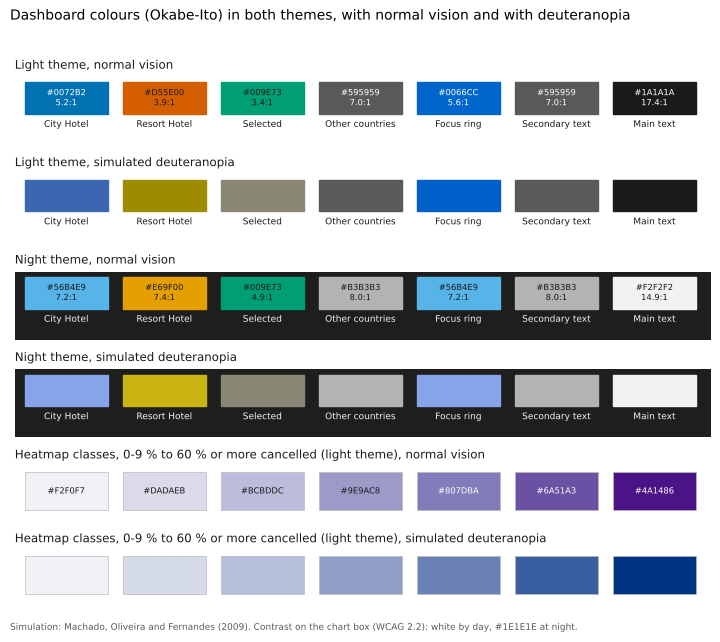

In [9]:
# ── Palette swatches: both themes, normal vision and simulated deuteranopia ──
SWATCHES = ['City Hotel', 'Resort Hotel', 'Selected country', 'Outline of the other countries', 'Focus ring',
            'Secondary text', 'Main text']
SHORT = {'Outline of the other countries': 'Other countries', 'Selected country': 'Selected'}
ROWS = [('light', False), ('light', True), ('night', False), ('night', True)]
fig, axes = plt.subplots(6, 1, figsize=(7.2, 6.4), gridspec_kw={'height_ratios': [1, 1, 1, 1, 0.8, 0.8]})
for ax, (theme, simulate) in zip(axes[:4], ROWS):
    card = CARDS[theme]
    ink = '#1A1A1A' if theme == 'light' else '#F2F2F2'
    ax.add_patch(plt.Rectangle((-0.1, -0.3), len(SWATCHES) + 0.1, 1.3, color=card, zorder=0))
    for position, use in enumerate(SWATCHES):
        hex_colour = dashboard_colours.loc[use, theme]
        shown = deuteranopia(hex_colour) if simulate else hex_colour
        ax.add_patch(plt.Rectangle((position, 0.3), 0.85, 0.6, color=shown))
        ax.text(position + 0.425, 0.18, SHORT.get(use, use), ha='center', va='top', fontsize=6.5, color=ink)
        if not simulate:
            ratio = contrast_ratio(hex_colour, card)
            label_ink = '#FFFFFF' if contrast_ratio(hex_colour, '#FFFFFF') > contrast_ratio(hex_colour, '#1A1A1A') else '#1A1A1A'
            ax.text(position + 0.425, 0.6, f'{hex_colour}\n{ratio:.1f}:1', ha='center', va='center', fontsize=6, color=label_ink)
    ax.set_xlim(-0.1, len(SWATCHES))
    ax.set_ylim(-0.3, 1)
    ax.set_title(f"{'Light' if theme == 'light' else 'Night'} theme, {'simulated deuteranopia' if simulate else 'normal vision'}",
                 loc='left', fontsize=8.5, color='#1A1A1A')
    ax.axis('off')
for ax, simulate in zip(axes[4:], [False, True]):
    for position, hex_colour in enumerate(PURPLES):
        shown = deuteranopia(hex_colour) if simulate else hex_colour
        ax.add_patch(plt.Rectangle((position, 0.2), 0.85, 0.7, color=shown, ec='#BBBBBB', lw=0.5))
        if not simulate:
            ink = '#1A1A1A' if relative_luminance(hex_colour) > 0.25 else '#FFFFFF'
            ax.text(position + 0.425, 0.55, hex_colour, ha='center', va='center', fontsize=6, color=ink)
    ax.set_xlim(-0.1, len(SWATCHES))
    ax.set_ylim(0, 1)
    ax.set_title(f"Heatmap classes, 0-9 % to 60 % or more cancelled (light theme), {'simulated deuteranopia' if simulate else 'normal vision'}",
                 loc='left', fontsize=8.5, color='#1A1A1A')
    ax.axis('off')
fig.suptitle('Dashboard colours (Okabe-Ito) in both themes, with normal vision and with deuteranopia', x=0.01, ha='left', fontsize=10)
fig.text(0.01, 0.01, 'Simulation: Machado, Oliveira and Fernandes (2009). Contrast on the chart box (WCAG 2.2): white by day, #1E1E1E at night.',
         fontsize=6.5, color='#595959')
fig.tight_layout(rect=(0, 0.03, 1, 0.96))
fig.savefig(IMAGES_DIR / 'palette_check.png', dpi=200)
plt.show()

### 4.3 Accessibility plan, item by item

Every item of the accessibility list of `spec.md` and of the WCAG 2.2 AA + COGA checklist of the `wcag-accessibility` skill, with how the design answers it. "Part 6" means it is built and tested in the browser there; Part 4 decides only the design.

In [10]:
# ── Accessibility plan (design decisions; tested in Part 6) ──────────────────
P4, P5, P6 = 'designed (Part 4)', 'planned (Part 5)', 'built and tested (Part 6)'
accessibility_plan = pd.DataFrame([
    # Course guidelines (01-Introduction, low vision guidelines H1-H18)
    ('Course', 'Title, legend, axis titles, caption, abbreviations explained, data source (H1-H7)', P4, 'Every chart: a question as title, a subtitle with the unit, axis titles, direct labels or a small legend, source and date in the footer, country names instead of ISO codes'),
    ('Course', 'Safe colours and contrast (H10-H11)', P4, 'Okabe-Ito palette; contrast checked above in both themes (all pass)'),
    ('Course', 'Legibility and resize (H12, H14)', P4, 'Text at least 12 px in charts and 16 px in the page; one column at 200 % zoom'),
    ('Course', 'Short alternative and long description (H8-H9)', P6, 'Each chart in a figure with a short and a long text alternative, and a Table button that shows its data table'),
    ('Course', 'Visible focus, device independence, customisation (H16-H18)', P5, 'Keyboard and mouse for every action; hotel and year filters; night mode; focus ring'),
    # Perception
    ('WCAG perception', 'Text contrast 4.5:1, graphics and UI 3:1', P4, 'Checked in section 4.2, light and night theme'),
    ('WCAG perception', 'Colour is never the only code', P4, 'Hotels: colour + line style + point shape + label; selected country: colour + band + bold label + outline + stripes + text; heatmap: colour + dots'),
    ('WCAG perception', 'Text alternative for each chart', P6, 'figcaption with sr-only short and long text'),
    ('WCAG perception', 'SVG renderer only', P6, 'vega-embed with renderer svg'),
    ('WCAG perception', 'Reduced motion respected; moving content can be paused (2.2.2)', P5, 'Only C9 moves, and only after Play; Pause and a month slider; one step every 1.5 s, no autoplay'),
    ('Pattern rules', 'Fill patterns when colour encodes categories; dots on heatmaps', P4, 'Heatmap (C2): dots whose density grows with the class; selected box (C7, C8): stripes; hotels are lines and dots, not filled areas; the map is a second view'),
    # Operability
    ('WCAG operability', 'Every data point reachable with the arrow keys; Alt + up/down between series', P5, 'Lines: points per month; heatmap cells; dumbbell dots; bubbles; boxes'),
    ('WCAG operability', 'Visible focus on every control and an SVG focus overlay on data points', P6, 'Overlay pattern of the skill'),
    ('WCAG operability', 'Selected category and exact value always visible next to the chart', P4, 'Value box of the focused mark; selected country and month in the filter panel'),
    ('WCAG operability', 'Previous / Next buttons disabled at the ends', P5, 'For the country selection'),
    ('WCAG operability', 'Touch / click targets at least 24 x 24 px (44 recommended)', P4, 'Buttons and selects 40 px high, every other control at least 24 px; smaller than the 44 px first planned, so each screen fits a 16:9 window'),
    ('WCAG operability', 'Skip link; no change of context on focus', P6, 'Skip links first in each page'),
    ('WCAG operability', 'Controls fit on mobile', 'adapted', 'Not applicable: desktop only (architecture.md); the page fits a 16:9 screen and turns into one column below 1100 px'),
    # Comprehensibility
    ('WCAG comprehensibility', 'Labels for every control; state changes announced (aria-live)', P5, 'Filter, selection and animation month announced'),
    ('WCAG comprehensibility', 'Page language declared', P6, 'html lang="en"'),
    ('WCAG comprehensibility', 'Data in an external file, not in the HTML', 'adapted', 'data.js loaded with script src instead of data.json (architecture.md, opens by double-click)'),
    ('WCAG comprehensibility', 'Plain-language titles; numbers with thousands separators and units', P4, 'Titles as questions; tooltips formatted'),
    ('WCAG comprehensibility', 'Active filters always visible; reset button always visible', P4, 'Filter panel with "Showing: ..." line and Reset button'),
    ('WCAG comprehensibility', 'At most 4 KPIs and 2-3 charts visible at once', P4, 'Main: 4 KPIs, 3 charts. Detail: 4 KPIs, 3 boxes: dumbbell or map (switch), bubbles, and the two box plots side by side as one view'),
    ('WCAG comprehensibility', 'Icons always with a text label; legends fixed and not truncated', P4, 'Direct labels; no icon-only buttons'),
    ('WCAG comprehensibility', 'Errors describe what happened and how to fix it', P6, 'Message when a filter leaves no data'),
    # Robustness and help
    ('WCAG robustness', 'Valid HTML; correct ARIA; SVG with role="img" and aria-label; 200 % zoom', P6, 'Checked in the browser'),
    ('Help page', 'accessibility.html linked from both screens, with keys, filters, shortcuts and a contact', P6, 'Link in the header of both screens'),
], columns=['source', 'item', 'status', 'how'])
accessibility_plan['status'].value_counts()

status
designed (Part 4)            12
built and tested (Part 6)     9
planned (Part 5)              5
adapted                       2
Name: count, dtype: int64

**Finding:** the design answers every item. Two items are adapted by decisions already in `architecture.md` (no mobile layout; data in `data.js`). The one moving chart (C9) only moves when Natalia asks for it and can be paused. Items about behaviour are planned in Part 5 and tested in Part 6.

## 6. Export

In [11]:
# ── Export ────────────────────────────────────────────────────────────────────
for old_file in ['contrast_checks.csv']:
    (OUTPUT_DIR / old_file).unlink(missing_ok=True)
cardinality.to_csv(OUTPUT_DIR / 'cardinality.csv')
planned_charts.to_csv(OUTPUT_DIR / 'planned_charts.csv', index=False)
draco_table.to_csv(OUTPUT_DIR / 'draco_hard_rules.csv', index=False)
contrast_table.to_csv(OUTPUT_DIR / 'contrast_checks.csv', index=False)
pair_table.to_csv(OUTPUT_DIR / 'colour_pairs_deuteranopia.csv', index=False)
scale_table.to_csv(OUTPUT_DIR / 'sequential_scales.csv', index=False)
accessibility_plan.to_csv(OUTPUT_DIR / 'accessibility_plan.csv', index=False)
sorted(p.name for p in OUTPUT_DIR.iterdir())

['accessibility_plan.csv',
 'cardinality.csv',
 'colour_pairs_deuteranopia.csv',
 'contrast_checks.csv',
 'draco_hard_rules.csv',
 'planned_charts.csv',
 'sequential_scales.csv']

## Conclusions

### Main findings
1. All eight charts pass the DRACO hard rules that apply to them; the map is outside DRACO and shares one box with the dumbbell, so no screen shows more than three charts.
2. All Okabe–Ito colours and the text pass the WCAG contrast minimums in the light and the night theme; the hotel pair and the selected green stay distinct in hue with deuteranopia, but the two hotels are close in lightness, so line style, point shape and labels are kept.
3. The two sequential scales keep their order with deuteranopia; their lightest classes are under 3:1, so the heatmap adds dots and every chart has a table.

### Limitations
- The deuteranopia simulation is a model; the final check is done in the browser in Part 6.
- With a country chosen from the list the country axis reaches 12 values, DRACO's soft limit.

### Suggested next steps
- Task 4.3: low-fidelity prototype of both screens (`lowfi_prototype.ipynb`).